# 04 - EMT-TF expression (unconditional final step)

The EMT-TF readout is produced regardless of gate outcomes; on this non-branching (Gate 2 GO /
Gate 3 NA) path it is the last notebook, numbered 04. A widened panel - Snail/Zeb/Twist **plus the
FOXC and PRRX mesenchymal families** (VIM is a mesenchymal marker, not a TF, and is excluded) - is
gated on detectable expression. On this single Gast/pSom -> Crest axis, **every** detectable EMT-TF
rises toward the neural-crest / mesenchymal terminus (all positive rho vs pseudotime); there is no
root-end EMT factor. The two most informative terminus-enriched factors (highest rho, distinct
families) are shown as a **categorical overlay** of thresholded expressers on a grey manifold.

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 16804 | pseudotime range 0.0 -> 12.17


### Score the EMT-TF panel along pseudotime

For each candidate TF present: detection fraction, mean expression in the early (root) vs late
(terminus) pseudotime third, and Spearman rho vs pseudotime. All EMT-TFs here are terminus-biased
(mean_late > mean_early, rho > 0), so the panel has **no early/root factor**. Among detectable
factors (frac > 0.03) the two most informative for marking the terminus are the highest-rho pair
from distinct TF families.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j, g in enumerate(present):
    x = X[:,j]; rho, p = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3),
                 round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t', ascending=False)
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03].copy()
fam = {'SNAI1':'Snail','SNAI2':'Snail','ZEB1':'Zeb','ZEB2':'Zeb','TWIST1':'Twist','TWIST2':'Twist',
       'FOXC1':'FOXC','FOXC2':'FOXC','PRRX1':'PRRX','PRRX2':'PRRX'}
ok['family'] = ok['TF'].map(fam)
# two most informative terminus factors from DIFFERENT families (highest rho)
sel_tfs, seen_fam = [], set()
for _, r in ok.sort_values('rho_vs_t', ascending=False).iterrows():
    if r['family'] in seen_fam: continue
    sel_tfs.append(r['TF']); seen_fam.add(r['family'])
    if len(sel_tfs) == 2: break
tf_hi, tf_lo = sel_tfs[0], sel_tfs[1]   # both terminus-enriched; tf_hi = strongest gradient
print(f'\ndetectable TFs (frac>0.03): {ok.TF.tolist()}  (all LATE/terminus-biased)')
print(f'shown pair (terminus-enriched, distinct families): {tf_hi} + {tf_lo}')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
  ZEB1      0.315       0.329      0.729     0.201 LATE(terminus)
 PRRX1      0.211       0.231      0.482     0.173 LATE(terminus)
TWIST1      0.085       0.078      0.208     0.142 LATE(terminus)
  ZEB2      0.397       0.509      0.835     0.122 LATE(terminus)
 SNAI2      0.048       0.043      0.120     0.119 LATE(terminus)
 FOXC1      0.011       0.009      0.027     0.064 LATE(terminus)
TWIST2      0.006       0.004      0.017     0.060 LATE(terminus)
 SNAI1      0.016       0.017      0.035     0.056 LATE(terminus)
 PRRX2      0.001       0.001      0.003     0.027 LATE(terminus)
 FOXC2      0.001       0.001      0.003     0.020 LATE(terminus)

detectable TFs (frac>0.03): ['ZEB1', 'PRRX1', 'TWIST1', 'ZEB2', 'SNAI2']  (all LATE/terminus-biased)
shown pair (terminus-enriched, distinct families): ZEB1 + PRRX1


### Deliverable - `expression.pdf`

Categorical overlay: cells above the upper-quartile-among-expressers threshold for each of the two
terminus-enriched factors, coloured over a grey manifold (display cutoffs set so the scale is not
outlier-dominated), `(3.5,1.5)` house aspect. Both factors mark the crest/mesenchymal terminus at
the right of the axis.

overlay thresholds (upper quartile among expressers): {'ZEB1': 1.794, 'PRRX1': 1.746} | cells shown: {'ZEB1': 1324, 'PRRX1': 888}
ZEB1: 31.5% expressing; 1324 shown (upper quartile), mean pseudotime of shown cells = 0.39 (all cells = 0.48)
PRRX1: 21.1% expressing; 888 shown (upper quartile), mean pseudotime of shown cells = 0.34 (all cells = 0.48)
saved expression.pdf


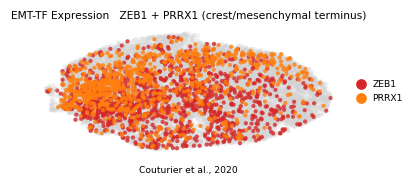

In [5]:
xl = adata.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo, yhi = np.percentile(xl[:,1],[0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [tf_hi, tf_lo]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [tf_hi, tf_lo]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [tf_hi, tf_lo]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [tf_hi, tf_lo]})
order = sorted([tf_hi, tf_lo], key=lambda g: -int(sel[g].sum()))
colors = {tf_hi:'tab:red', tf_lo:'tab:orange'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([],[],marker='o',ls='',color=colors[g],label=g) for g in [tf_hi,tf_lo]],
          frameon=False, loc='center left', bbox_to_anchor=(1.02,.5), fontsize=6, handletextpad=.2)
ax.set_title(f'EMT-TF Expression   {tf_hi} + {tf_lo} (crest/mesenchymal terminus)', size=7.0)
ax.text(.5, -.14, 'Couturier et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight'); plt.show()
for g in [tf_hi, tf_lo]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
print('saved expression.pdf')